# MovieLens 1M：数据探索与预处理

依次运行全部单元格，查看数据特点并生成后续算法使用的输入。
数据来源：[GroupLens MovieLens 1M](https://grouplens.org/datasets/movielens/1m/)。

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
                    if (path / 'src' / 'data.py').is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import (load_movielens, resolve_data_dir, dataset_summary, column_summary,
                      clean_ratings, chronological_split, add_relevance_labels,
                      split_summary, validate_splits)
from src.features import (build_model_inputs, build_evaluation_context, evaluation_summary,
                          build_preprocessing_config, save_preprocessed_artifacts)

DATA_DIR = None  # 数据不在默认目录时，在这里填写路径。
data_dir = resolve_data_dir(DATA_DIR)
tables = load_movielens(data_dir)
users, movies, ratings = (tables[name] for name in ['users', 'movies', 'ratings'])
TABLE_DIR = PROJECT_ROOT / 'outputs' / 'tables'
FIGURE_DIR = PROJECT_ROOT / 'outputs' / 'figures'
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
%matplotlib inline

## 1. 数据概况

`users` 保存用户及人口属性，`movies` 保存电影标题与类型，`ratings` 保存评分及时间戳。
数据对比表展示各表形状、缺失值、含缺失值的列及重复行；字段表展示数据类型、缺失数和唯一值数量。

In [2]:
display(dataset_summary(tables))
display(column_summary(tables))

,rows,columns,missing_values,columns_with_missing,duplicate_rows
table,,,,,
users,6040,5,0,(none),0
movies,3883,3,0,(none),0
ratings,1000209,4,0,(none),0


dtype  missing_values  unique_values
table   column                                           
users   user_id      Int64               0           6040
        gender      string               0              2
        age          Int64               0              7
        occupation   Int64               0             21
        zip_code    string               0           3439
movies  movie_id     Int64               0           3883
        title       string               0           3883
        genres      string               0            301
ratings user_id      Int64               0           6040
        movie_id     Int64               0           3706
        rating       Int64               0              5
        timestamp    Int64               0         458455

## 2. 数据探索

查看评分、用户活跃度、电影热度和类型分布。电影可属于多个类型；这些全量统计仅用于探索，训练特征在划分后构造。

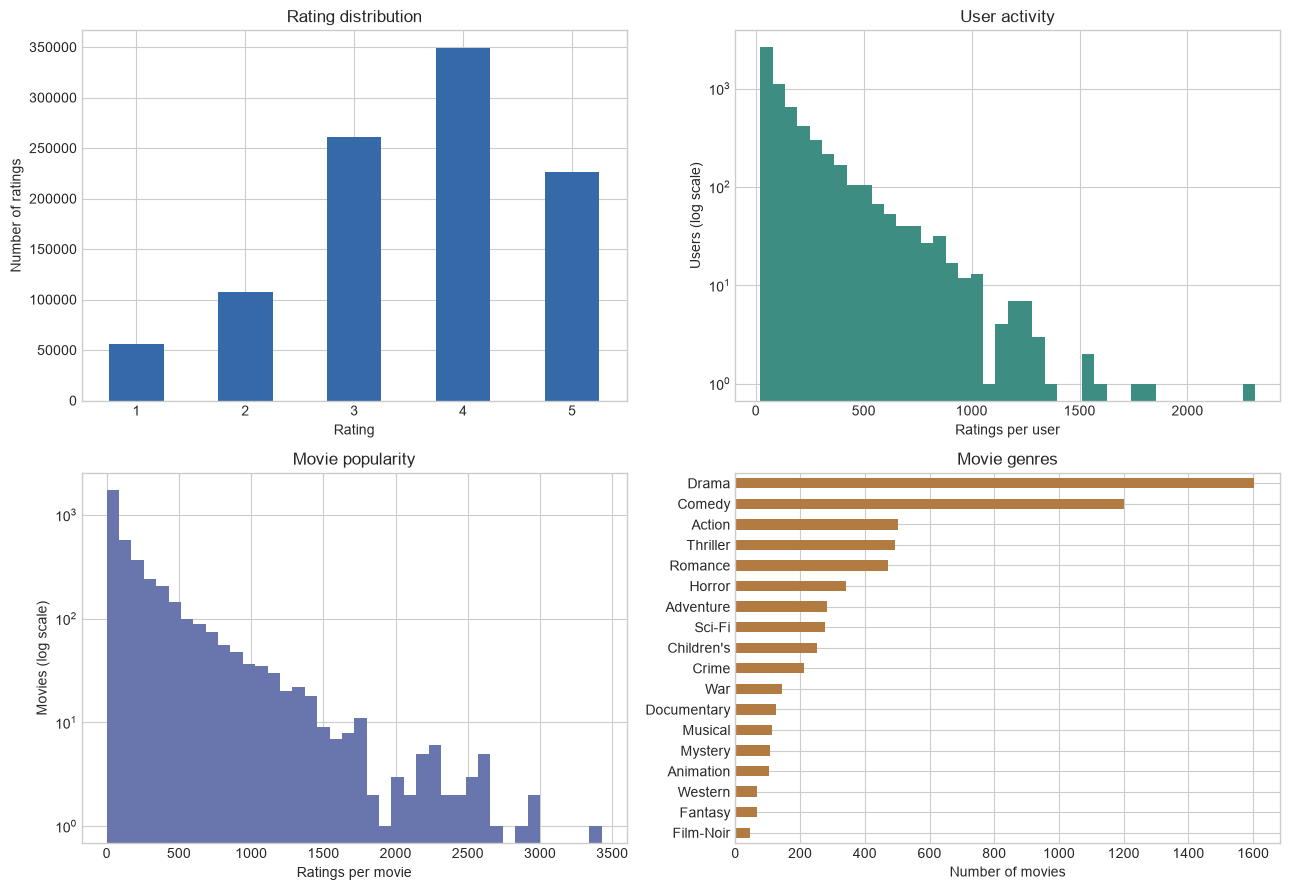

平均评分 **3.58**，4–5 分占 **57.52%**；每人评分中位数为 **96** 部，有 **177** 部电影没有评分。用户—电影交互稀疏度为 **95.74%**。评分与热度分布不均，未评分表示偏好未知。

In [3]:
rating_counts = ratings['rating'].value_counts().reindex(range(1, 6), fill_value=0)
user_counts = ratings.groupby('user_id').size().reindex(users['user_id'], fill_value=0)
movie_counts = ratings.groupby('movie_id').size().reindex(movies['movie_id'], fill_value=0)
genre_counts = movies['genres'].str.split('|', regex=False).explode().value_counts()
observed_pairs = ratings[['user_id', 'movie_id']].drop_duplicates().shape[0]
sparsity = 1 - observed_pairs / (users['user_id'].nunique() * movies['movie_id'].nunique())

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
rating_counts.plot.bar(ax=axes[0, 0], color='#3569a8', rot=0)
axes[0, 0].set(title='Rating distribution', xlabel='Rating', ylabel='Number of ratings')
axes[0, 1].hist(user_counts.to_numpy(dtype=int), bins=40, color='#3d8d83')
axes[0, 1].set(title='User activity', xlabel='Ratings per user', ylabel='Users (log scale)', yscale='log')
axes[1, 0].hist(movie_counts.to_numpy(dtype=int), bins=40, color='#6975ad')
axes[1, 0].set(title='Movie popularity', xlabel='Ratings per movie', ylabel='Movies (log scale)', yscale='log')
genre_counts.sort_values().plot.barh(ax=axes[1, 1], color='#b27b42')
axes[1, 1].set(title='Movie genres', xlabel='Number of movies', ylabel='')
fig.tight_layout()
fig.savefig(FIGURE_DIR / '01_data_overview.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

display(Markdown(
    f'平均评分 **{ratings["rating"].mean():.2f}**，4–5 分占 **{ratings["rating"].ge(4).mean():.2%}**；'
    f'每人评分中位数为 **{user_counts.median():.0f}** 部，'
    f'有 **{movie_counts.eq(0).sum():,}** 部电影没有评分。'
    f'用户—电影交互稀疏度为 **{sparsity:.2%}**。评分与热度分布不均，未评分表示偏好未知。'
))

## 3. 清洗、划分与标签

清洗缺失、无效及完全重复的评分；有冲突的重复用户—电影记录会报错。
按每位用户的评分时间约 **80% / 10% / 10%** 划分训练、验证和测试集，同时间戳记录放在同一集合；不足三个时间组的用户仅进入训练集。
划分后将 **评分 ≥4** 标为正反馈，1–3 分记录仍用于历史过滤。评分时间不一定是观影时间。

In [4]:
SPLIT_RATIOS = (0.8, 0.1, 0.1)
RELEVANCE_THRESHOLD = 4
EVALUATION_K = 10

cleaned_ratings, cleaning_audit = clean_ratings(tables)
splits = chronological_split(cleaned_ratings, SPLIT_RATIOS)
splits = add_relevance_labels(splits, RELEVANCE_THRESHOLD)
split_checks = validate_splits(splits, cleaned_ratings)
partition_summary = split_summary(splits)
print(f'清洗删除 {len(ratings) - len(cleaned_ratings):,} 条记录；时间划分检查通过。')
display(partition_summary[['rows', 'row_share', 'users', 'movies', 'positive_rows']]
        .style.format({'row_share': '{:.2%}'}))

清洗删除 0 条记录；时间划分检查通过。


,rows,row_share,users,movies,positive_rows
split,,,,,
train,799086,79.89%,6040,3667,470016
validation,100613,10.06%,6039,3372,53535
test,100510,10.05%,6039,3442,51730


## 4. 特征编码

所有 ID 映射、交互矩阵及电影类型词表只根据训练集构造，避免留出评分进入训练特征。

| 输入 | 编码 |
|---|---|
| 用户 / 电影 ID | 连续整数索引 |
| 显式评分矩阵 | 保留 1–5 分，未评分为 0；CSR 稀疏存储 |
| 正反馈矩阵 | 评分 ≥4 为 1，其余为 0；ItemCF 使用此矩阵 |
| 电影类型 | 多标签 0/1 编码，供后续内容模型使用 |
| 正反馈序列 | 按评分时间排列，电影 token 为索引 +1，0 留作 padding |

年龄、职业属于类别编码；当前 ItemCF 不使用人口属性，也不对类别 ID 做数值归一化。

In [5]:
model_inputs = build_model_inputs(splits['train'], movies)
model_input_summary = pd.DataFrame([
    (name, *matrix.shape, matrix.nnz)
    for name, matrix in [
        ('explicit_ratings', model_inputs.explicit_ratings),
        ('positive_interactions', model_inputs.positive_interactions),
        ('genre_features', model_inputs.genre_features),
    ]
], columns=['input', 'rows', 'columns', 'nonzero_values']).set_index('input')
display(model_input_summary)

,rows,columns,nonzero_values
input,,,
explicit_ratings,6040,3667,799086
positive_interactions,6040,3667,470016
genre_features,3667,18,6145


## 5. 统一评估规则

验证使用训练历史，测试使用训练加验证历史；模型参数只在训练集拟合。
候选为训练目录中用户尚未评分的电影，目标为留出集中评分 ≥4 的候选电影。
三种算法使用相同的评估用户：有训练正反馈、至少一个目标且至少有 10 个候选。Top-10 是本项目的评估设置。

In [6]:
evaluation_contexts = {
    stage: build_evaluation_context(splits, model_inputs, stage, k=EVALUATION_K)
    for stage in ['validation', 'test']
}
cohort_summary = evaluation_summary(evaluation_contexts)
display(cohort_summary[['eligible_users', 'eligible_relevant_pairs', 'positive_pairs_with_cold_movie']])

,eligible_users,eligible_relevant_pairs,positive_pairs_with_cold_movie
stage,,,
validation,5776,53530,5
test,5765,51717,13


## 6. 保存模型输入

输入保存到 `data/processed/`，配置记录划分规则、源文件校验和和软件版本。当前流程没有随机步骤。

In [7]:
config = build_preprocessing_config(
    data_dir, cleaned_ratings, split_ratios=SPLIT_RATIOS,
    relevance_threshold=RELEVANCE_THRESHOLD, evaluation_k=EVALUATION_K,
)
save_preprocessed_artifacts(
    splits, model_inputs, evaluation_contexts, PROJECT_ROOT / 'data' / 'processed', config,
)
for name, frame in {
    'cleaning_audit': cleaning_audit, 'split_summary': partition_summary,
    'split_checks': split_checks, 'model_input_summary': model_input_summary,
    'evaluation_cohorts': cohort_summary,
}.items():
    frame.to_csv(TABLE_DIR / f'{name}.csv', encoding='utf-8-sig')
print('预处理完成。下一步在项目根目录运行：python train.py --model itemcf')

预处理完成。下一步在项目根目录运行：python train.py --model itemcf
